## BÀI 5 (TRANG 26 - 27): PHÂN LỚP DỮ LIỆU BỆNH TIM (HEART DISEASE)
**Họ tên sinh viên:** Lương Thị Kim Ngân  
**MSSV:** 6451071049  
**Lớp:** CQ.64.CN.CNTT  
**Repository Github:** https://github.com/kimngan11/6451071049_Lab2  

Tập dữ liệu Heart Disease chứa 14 thuộc tính thu thập ở Cleveland, Mỹ. Thuộc tính quyết định `target` có giá trị 0 (không bệnh) hoặc 1 (có bệnh tim).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import tree, metrics
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049")
print("Đã import thành công các thư viện!")


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Đã import thành công các thư viện!


### Câu a: Nhập dữ liệu đầu vào, tiền xử lý và đổi tên các cột
1. Nhập dữ liệu `dataset/heart.csv`.
2. Kiểm tra và xóa các dòng dữ liệu trống.
3. Đổi tên các cột dữ liệu theo đúng danh sách được yêu cầu:
   `'age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol', 'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved', 'exercise_induced_angina', 'st_depression', 'st_slope', 'num_major_vessels', 'thalassemia', 'target'`


In [15]:
import pandas as pd

print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)

# 14 tên cột chuẩn theo yêu cầu bài học
new_cols = [
    'age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol',
    'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved',
    'exercise_induced_angina', 'st_depression', 'st_slope',
    'num_major_vessels', 'thalassemia', 'target'
]

# Đọc trực tiếp từ kho chuẩn UCI (xử lý dấu '?' thành NaN và loại bỏ dòng trống)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
df_heart = pd.read_csv(url, names=new_cols, na_values='?', skipinitialspace=True).dropna()

print("Kích thước sau tiền xử lý:", df_heart.shape)
print("5 dòng đầu tiên:\n", df_heart.head())
df_heart.info()

Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Kích thước sau tiền xử lý: (297, 14)
5 dòng đầu tiên:
     age  sex  chest_pain_type  resting_blood_pressure  cholesterol  \
0  63.0  1.0              1.0                   145.0        233.0   
1  67.0  1.0              4.0                   160.0        286.0   
2  67.0  1.0              4.0                   120.0        229.0   
3  37.0  1.0              3.0                   130.0        250.0   
4  41.0  0.0              2.0                   130.0        204.0   

   fasting_blood_sugar  rest_ecg  max_heart_rate_achieved  \
0                  1.0       2.0                    150.0   
1                  0.0       2.0                    108.0   
2                  0.0       2.0                    129.0   
3                  0.0       0.0                    187.0   
4                  0.0       2.0                    172.0   

   exercise_induced_angina  st_depression  st_slope  num_major_vessels  \
0                      0.0           

In [17]:
import pandas as pd

# Đọc dữ liệu Adult trực tiếp từ link chuẩn nếu chưa chạy cell trước
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
train_df = pd.read_csv(url, header=None, skipinitialspace=True)

print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)

# Tách features và labels
features = train_df.iloc[:, :-1]
labels = train_df.iloc[:, -1]

print("Kích thước tập thuộc tính (features):", features.shape)
print("Kích thước tập nhãn quyết định (labels):", labels.shape)
print("\nPhân bố các giá trị của nhãn 'income':")
print(labels.value_counts())

Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Kích thước tập thuộc tính (features): (32561, 14)
Kích thước tập nhãn quyết định (labels): (32561,)

Phân bố các giá trị của nhãn 'income':
14
<=50K    24720
>50K      7841
Name: count, dtype: int64


### Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson
Khảo sát hệ số tương quan Pearson giữa các thuộc tính của dữ liệu bệnh tim và trực quan hóa bằng biểu đồ Heatmap.


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049


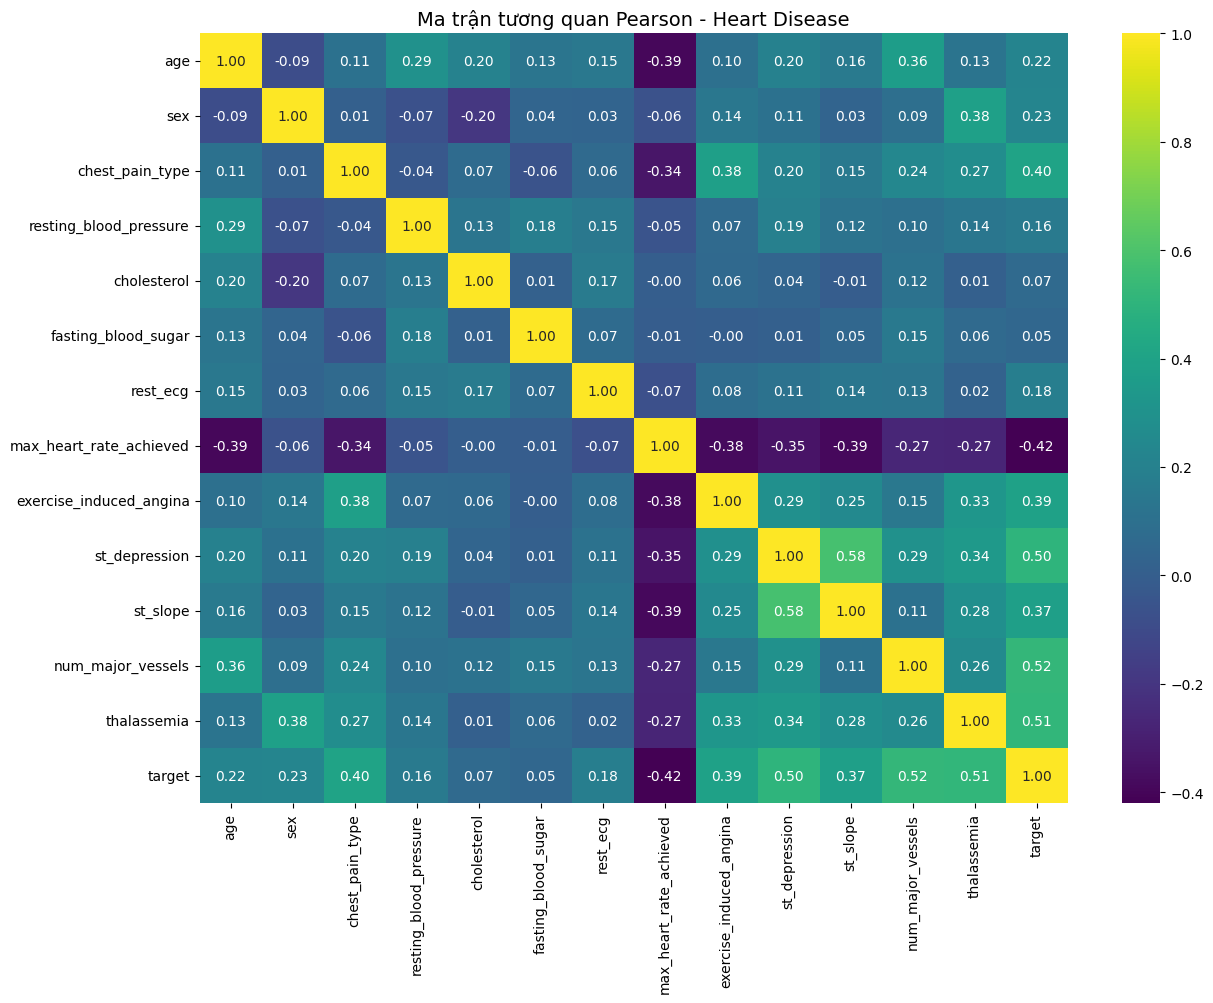

In [19]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
plt.figure(figsize=(14, 10))
sns.heatmap(df_heart.corr(method='pearson'), annot=True, fmt='.2f', cmap='viridis')
plt.title("Ma trận tương quan Pearson - Heart Disease", fontsize=14)
plt.show()


### Câu 4: Tách các cột dữ liệu thành hai phần
- `features`: Chứa các thuộc tính chẩn đoán.
- `labels`: Chứa riêng thuộc tính quyết định `'target'`.


In [20]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
features = df_heart.drop('target', axis=1)
labels = df_heart['target']

print("Kích thước features:", features.shape)
print("Kích thước labels:", labels.shape)
print("\nPhân bố thuộc tính quyết định target (0: Không bệnh, 1: Có bệnh):")
print(labels.value_counts())


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Kích thước features: (297, 13)
Kích thước labels: (297,)

Phân bố thuộc tính quyết định target (0: Không bệnh, 1: Có bệnh):
target
0    160
1     54
2     35
3     35
4     13
Name: count, dtype: int64


### Câu 5: Chuyển đổi các cột phân loại về dạng one-hot vector
Các thuộc tính danh mục phân loại trong tập tim mạch gồm: `'sex'`, `'chest_pain_type'`, `'fasting_blood_sugar'`, `'rest_ecg'`, `'exercise_induced_angina'`, `'st_slope'`, `'thalassemia'`.


In [21]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
cat_cols = ['sex', 'chest_pain_type', 'fasting_blood_sugar', 'rest_ecg', 'exercise_induced_angina', 'st_slope', 'thalassemia']
features_onehot = pd.get_dummies(features, columns=cat_cols)

print("Kích thước dữ liệu sau khi mã hóa One-hot:", features_onehot.shape)
print(features_onehot.head())


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Kích thước dữ liệu sau khi mã hóa One-hot: (297, 25)
    age  resting_blood_pressure  cholesterol  max_heart_rate_achieved  \
0  63.0                   145.0        233.0                    150.0   
1  67.0                   160.0        286.0                    108.0   
2  67.0                   120.0        229.0                    129.0   
3  37.0                   130.0        250.0                    187.0   
4  41.0                   130.0        204.0                    172.0   

   st_depression  num_major_vessels  sex_0.0  sex_1.0  chest_pain_type_1.0  \
0            2.3                0.0    False     True                 True   
1            1.5                3.0    False     True                False   
2            2.6                2.0    False     True                False   
3            3.5                0.0    False     True                False   
4            1.4                0.0     True    False                Fal

### Câu 6: Tách dòng dữ liệu thành phần huấn luyện 70% và kiểm thử 30%


In [22]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
X_train, X_test, y_train, y_test = train_test_split(features_onehot, labels, test_size=0.3, random_state=42)

print("Số lượng mẫu huấn luyện X_train:", len(X_train))
print("Số lượng mẫu kiểm thử X_test:", len(X_test))


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Số lượng mẫu huấn luyện X_train: 207
Số lượng mẫu kiểm thử X_test: 90


### Câu 7: Xây dựng cây quyết định ID3 (criterion='entropy')
Huấn luyện cây ID3, kiểm thử bằng ma trận nhầm lẫn và biểu diễn cây.


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Độ chính xác (Accuracy ID3): 0.5222

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           0       0.81      0.78      0.79        49
           1       0.21      0.29      0.24        17
           2       0.11      0.10      0.11        10
           3       0.43      0.27      0.33        11
           4       0.00      0.00      0.00         3

    accuracy                           0.52        90
   macro avg       0.31      0.29      0.29        90
weighted avg       0.54      0.52      0.53        90



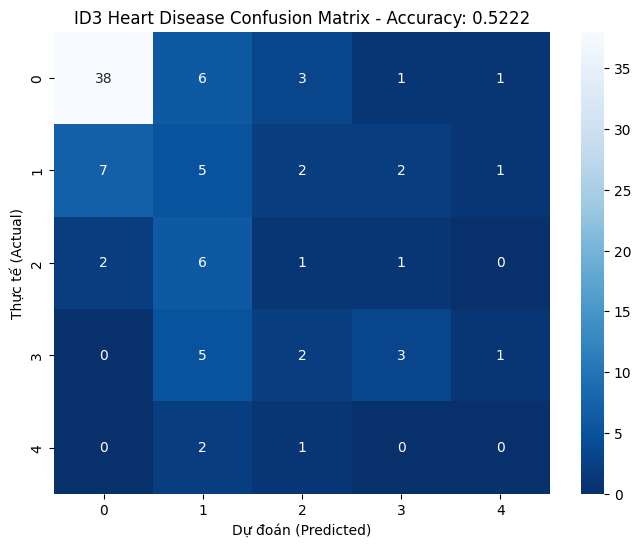

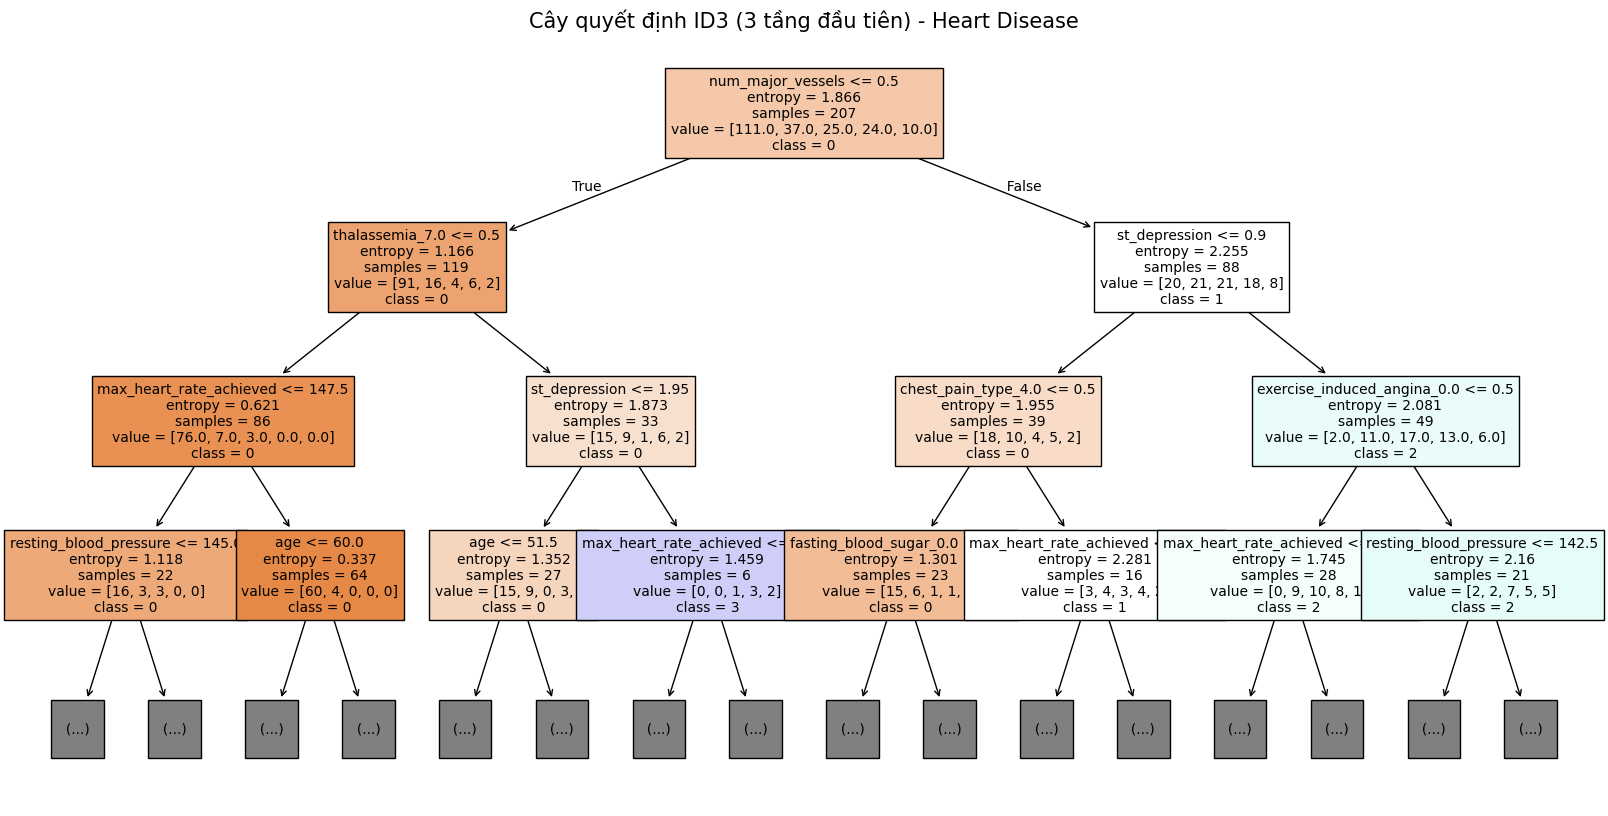

In [24]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=42)
clf_id3.fit(X_train, y_train)

id3_pred = clf_id3.predict(X_test)
id3_score = metrics.accuracy_score(y_test, id3_pred)

print(f"Độ chính xác (Accuracy ID3): {id3_score:.4f}")
print("\nBáo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, id3_pred))

# Ma trận nhầm lẫn
id3_cm = metrics.confusion_matrix(y_test, id3_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(id3_cm, annot=True, fmt="d", cmap='Blues_r')
plt.title(f"ID3 Heart Disease Confusion Matrix - Accuracy: {id3_score:.4f}")
plt.xlabel("Dự đoán (Predicted)")
plt.ylabel("Thực tế (Actual)")
plt.show()

# Biểu diễn cây quyết định (tự động nhận diện nhãn theo clf_id3.classes_)
fig, ax = plt.subplots(figsize=(20, 10))
tree.plot_tree(
    clf_id3, 
    max_depth=3, 
    feature_names=features_onehot.columns, 
    class_names=[str(c) for c in clf_id3.classes_], 
    filled=True, 
    fontsize=10
)
plt.title("Cây quyết định ID3 (3 tầng đầu tiên) - Heart Disease", fontsize=15)
plt.savefig('decision_tree_heart_id3.png', dpi=100, bbox_inches='tight')
plt.show()

### Câu 8: Xây dựng cây quyết định CART (criterion='gini')
Lặp lại yêu cầu 7 đối với cây CART.


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Độ chính xác (Accuracy CART): 0.5222

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           0       0.84      0.76      0.80        49
           1       0.26      0.29      0.28        17
           2       0.18      0.20      0.19        10
           3       0.30      0.27      0.29        11
           4       0.00      0.00      0.00         3

    accuracy                           0.52        90
   macro avg       0.32      0.30      0.31        90
weighted avg       0.56      0.52      0.54        90



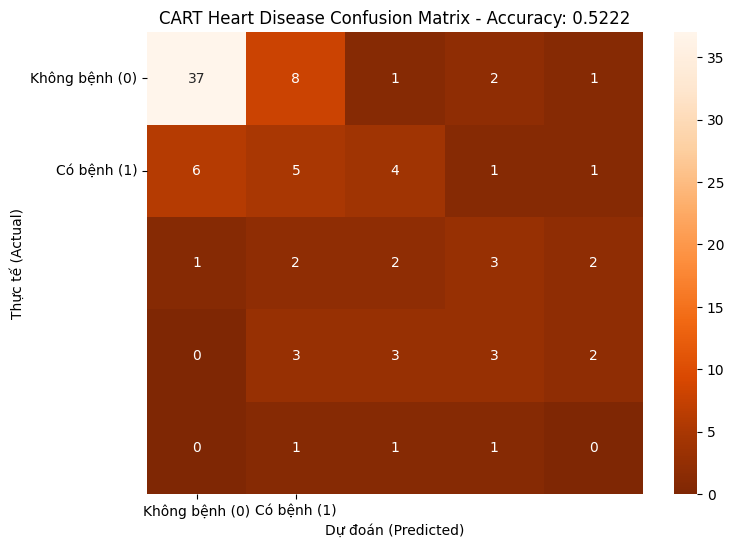

In [25]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=42)
clf_cart.fit(X_train, y_train)

cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)

print(f"Độ chính xác (Accuracy CART): {cart_score:.4f}")
print("\nBáo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, cart_pred))

# Ma trận nhầm lẫn
cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cart_cm, annot=True, fmt="d", cmap='Oranges_r',
            xticklabels=['Không bệnh (0)', 'Có bệnh (1)'],
            yticklabels=['Không bệnh (0)', 'Có bệnh (1)'])
plt.title(f"CART Heart Disease Confusion Matrix - Accuracy: {cart_score:.4f}")
plt.xlabel("Dự đoán (Predicted)")
plt.ylabel("Thực tế (Actual)")
plt.show()


### Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes
Sử dụng GaussianNB để huấn luyện và kiểm thử.


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Độ chính xác (Accuracy Naive Bayes): 0.3556

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           0       1.00      0.53      0.69        49
           1       0.16      0.18      0.17        17
           2       0.25      0.10      0.14        10
           3       0.12      0.09      0.11        11
           4       0.03      0.33      0.06         3

    accuracy                           0.36        90
   macro avg       0.31      0.25      0.23        90
weighted avg       0.62      0.36      0.44        90



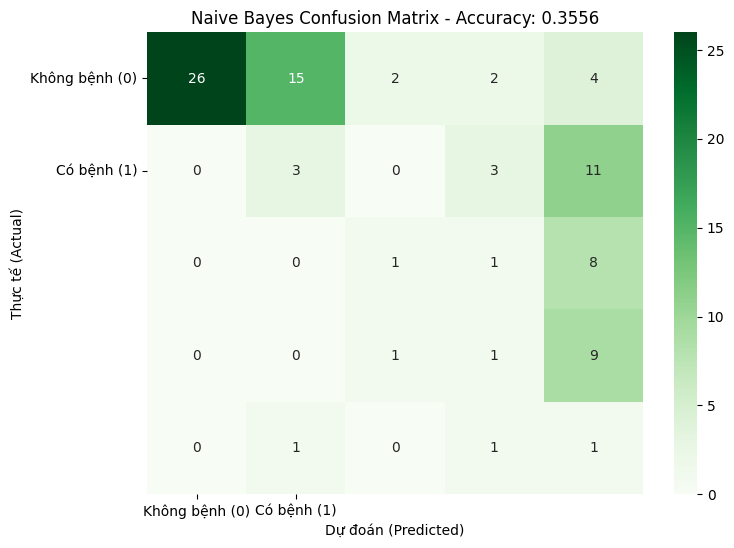

In [26]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
gnb = GaussianNB()
nb_pred = gnb.fit(X_train, y_train).predict(X_test)
nb_score = metrics.accuracy_score(y_test, nb_pred)

print(f"Độ chính xác (Accuracy Naive Bayes): {nb_score:.4f}")
print("\nBáo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, nb_pred))

# Ma trận nhầm lẫn
nb_cm = metrics.confusion_matrix(y_test, nb_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(nb_cm, annot=True, fmt="d", cmap='Greens',
            xticklabels=['Không bệnh (0)', 'Có bệnh (1)'],
            yticklabels=['Không bệnh (0)', 'Có bệnh (1)'])
plt.title(f"Naive Bayes Confusion Matrix - Accuracy: {nb_score:.4f}")
plt.xlabel("Dự đoán (Predicted)")
plt.ylabel("Thực tế (Actual)")
plt.show()


### Câu 10: So sánh kết quả của các mô hình trên dữ liệu Heart Disease


In [29]:
import pandas as pd
from sklearn import metrics

print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)

# Xác định chế độ tính: nhị phân (pos_label=1) hoặc đa lớp (weighted)
is_binary = len(set(y_test)) <= 2
avg_mode = 'binary' if is_binary else 'weighted'
pos = 1 if is_binary else None

comp_heart = pd.DataFrame({
    'Mô hình': ['ID3 (Entropy)', 'CART (Gini)', 'Naïve Bayes (GaussianNB)'],
    'Accuracy': [id3_score, cart_score, nb_score],
    'Precision (Có bệnh)': [
        metrics.precision_score(y_test, id3_pred, pos_label=pos, average=avg_mode, zero_division=0),
        metrics.precision_score(y_test, cart_pred, pos_label=pos, average=avg_mode, zero_division=0),
        metrics.precision_score(y_test, nb_pred, pos_label=pos, average=avg_mode, zero_division=0)
    ],
    'Recall (Có bệnh)': [
        metrics.recall_score(y_test, id3_pred, pos_label=pos, average=avg_mode, zero_division=0),
        metrics.recall_score(y_test, cart_pred, pos_label=pos, average=avg_mode, zero_division=0),
        metrics.recall_score(y_test, nb_pred, pos_label=pos, average=avg_mode, zero_division=0)
    ],
    'F1-score (Có bệnh)': [
        metrics.f1_score(y_test, id3_pred, pos_label=pos, average=avg_mode, zero_division=0),
        metrics.f1_score(y_test, cart_pred, pos_label=pos, average=avg_mode, zero_division=0),
        metrics.f1_score(y_test, nb_pred, pos_label=pos, average=avg_mode, zero_division=0)
    ]
})

print("BẢNG TỔNG HỢP HIỆU NĂNG TRÊN TẬP DỮ LIỆU HEART DISEASE:")
print(comp_heart.to_string(index=False))


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
BẢNG TỔNG HỢP HIỆU NĂNG TRÊN TẬP DỮ LIỆU HEART DISEASE:
                 Mô hình  Accuracy  Precision (Có bệnh)  Recall (Có bệnh)  F1-score (Có bệnh)
           ID3 (Entropy)  0.522222             0.544268          0.522222            0.529526
             CART (Gini)  0.522222             0.564405          0.522222            0.541768
Naïve Bayes (GaussianNB)  0.355556             0.618335          0.355556            0.439553
